# From sequencing reads to a PyroPPI counts table

The other vignettes start at `counts.csv`. This one produces it.

A PPI Recorder scan is sequenced twice.
The dictionary library pairs each barcode with the construct it names: barcodes in R1, construct sequence in R2.
The cDNA library reads the reporter, where each read carries a barcode and the edit template.

Build the dictionary once, then apply it to the cDNA for reads and edits per construct, which are PyroPPI's `total` and `edited`.

Reads are in `scripts/read_processing/example_data`: two datasets subset from the production RAD51C scan, each shipped with the output the pipeline produces.

Needs pandas, matplotlib, pysam, and bowtie2 and samtools on the PATH.

In [1]:
import sys
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

here = Path.cwd()
repo = next(p for p in [here, *here.parents] if (p / "data" / "rad51x9").is_dir())

# The vignette script beside this notebook holds the pipeline-driving helpers
# and the figures, so both forms run the same code.
sys.path.insert(0, str(repo / "vignettes" / "reads_to_counts"))
import reads_to_counts as vignette  # noqa: E402

work = Path(tempfile.mkdtemp(prefix="pyroppi-reads-"))
figures = repo / "vignettes" / "reads_to_counts"
print(f"pipeline:     {vignette.PIPELINE.relative_to(repo)}")
print(f"example data: {vignette.EXAMPLES.relative_to(repo)}")
print("intermediates in a temporary directory")

pipeline:     scripts/read_processing
example data: scripts/read_processing/example_data
intermediates in a temporary directory


## The two example datasets

Both are RAD51C against wild-type XRCC3, driven by the same cDNA sample, tiling different blocks.

`Dual_NEBuilder` cloning puts several constructs behind one barcode, so step 3 keeps a barcode on a plurality of its reads.
`regular` cloning gives about one construct per barcode and demands near-unanimity.

In [2]:
pd.DataFrame(vignette.DATASETS).T.rename_axis("dataset")

,reference,prefix,min_support,min_purity
dataset,,,,
Dual_NEBuilder,RAD51C_blk_1,RAD51C_DMS_1,5,0.1
regular,RAD51C_blk_3,RAD51C_DMS_3,3,0.9


In [3]:
for name in vignette.DATASETS:
    print(name)
    for path in sorted((vignette.EXAMPLES / name).rglob("*")):
        if path.is_file():
            rel = path.relative_to(vignette.EXAMPLES / name)
            print(f"  {rel!s:58s} {path.stat().st_size / 1024:7.0f} kB")

Dual_NEBuilder
  cdna_edit_count/NR-TV_HCT_RAD51C_XRCC3_Rep1__R1.fastq.gz       381 kB
  dict_build/RAD51C_DMS_1_Dictionary_R1.fastq.gz                 510 kB
  dict_build/RAD51C_DMS_1_Dictionary_R2.fastq.gz                 657 kB
  expected_output/NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv       2 kB
  expected_output/RAD51C_DMS_1.barcode_to_variant.csv.gz           1 kB
regular
  cdna_edit_count/NR-TV_HCT_RAD51C_XRCC3_Rep1__R1.fastq.gz       390 kB
  dict_build/RAD51C_DMS_3_Dictionary_R1.fastq.gz                 563 kB
  dict_build/RAD51C_DMS_3_Dictionary_R2.fastq.gz                1262 kB
  expected_output/NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv       2 kB
  expected_output/RAD51C_DMS_3.barcode_to_variant.csv.gz           1 kB


## What has to be installed

The cDNA half needs pandas.
The dictionary half needs pysam, from the `reads` extra, plus bowtie2 and samtools, which pip does not install.

In [4]:
for name, found in vignette.requirements().items():
    print(f"{name:14s} {'found' if found else 'NOT FOUND'}")

bowtie2        found
bowtie2-build  found
samtools       found
pysam          found


## Part 1, building the barcode dictionary

`step1_extract_barcodes.py` pulls bc1, bc2 and the construct sequence from each read pair into a FASTA headed `bc1_bc2_<n>`.
bowtie2 aligns those; samtools sorts them.
`step2_map_constructs.py` matches each read's mismatches against the designed library.
`step3_build_dictionary.py` collapses a barcode's reads to the construct most agree on, then applies the support and purity cutoffs.

`--reference` selects the row in each of the three library files: the reference FASTA, the construct library, the R2 fixed-sequence table.

In [5]:
ref, index = vignette.prepare_reference(work, work / "reference.log")

dictionaries, tallies, raws = {}, {}, {}
for name, spec in vignette.DATASETS.items():
    print(f"\n{name}  (--reference {spec['reference']})")
    dictionaries[name], tallies[name] = vignette.build_dictionary(name, work, ref, index)
    raws[name] = vignette.read_raw_dictionary(
        dictionaries[name].parent / "raw_dict.csv.gz",
        spec["min_support"], spec["min_purity"],
    )

  samtools faidx
  bowtie2-build



Dual_NEBuilder  (--reference RAD51C_blk_1)
  step1_extract_barcodes.py


  bowtie2 | samtools sort


  step2_map_constructs.py


  step3_build_dictionary.py

regular  (--reference RAD51C_blk_3)
  step1_extract_barcodes.py


  bowtie2 | samtools sort


  step2_map_constructs.py


  step3_build_dictionary.py


In [6]:
for name, path in dictionaries.items():
    table = vignette.read_dictionary(path)
    print(f"{name}: {len(table)} barcodes kept of {len(raws[name])} seen, "
          f"over {table.construct.nunique()} constructs")

vignette.read_dictionary(dictionaries["Dual_NEBuilder"]).head()

Dual_NEBuilder: 62 barcodes kept of 75 seen, over 26 constructs
regular: 75 barcodes kept of 75 seen, over 27 constructs


,barcode,construct,support,reads,purity,bc1
0,AAAGCTGGGGACCA_,RAD51C---G113D,14,61,0.229508,AAAGCTGGGGACCA
1,AAATTGCCGGGGGG_,RAD51C---G113D,9,39,0.230769,AAATTGCCGGGGGG
2,AACCCCGTAACTCGG_,RAD51C---G113V,11,53,0.207547,AACCCCGTAACTCGG
3,AAGAGGAATTTGG_,RAD51C---I110V,9,53,0.169811,AAGAGGAATTTGG
4,AAGCTTGGTGGGC_,RAD51C---G113V,7,38,0.184211,AAGCTTGGTGGGC


Each row: barcode, construct, supporting reads, total reads, purity.

Support against purity for every barcode, before either cutoff ran:

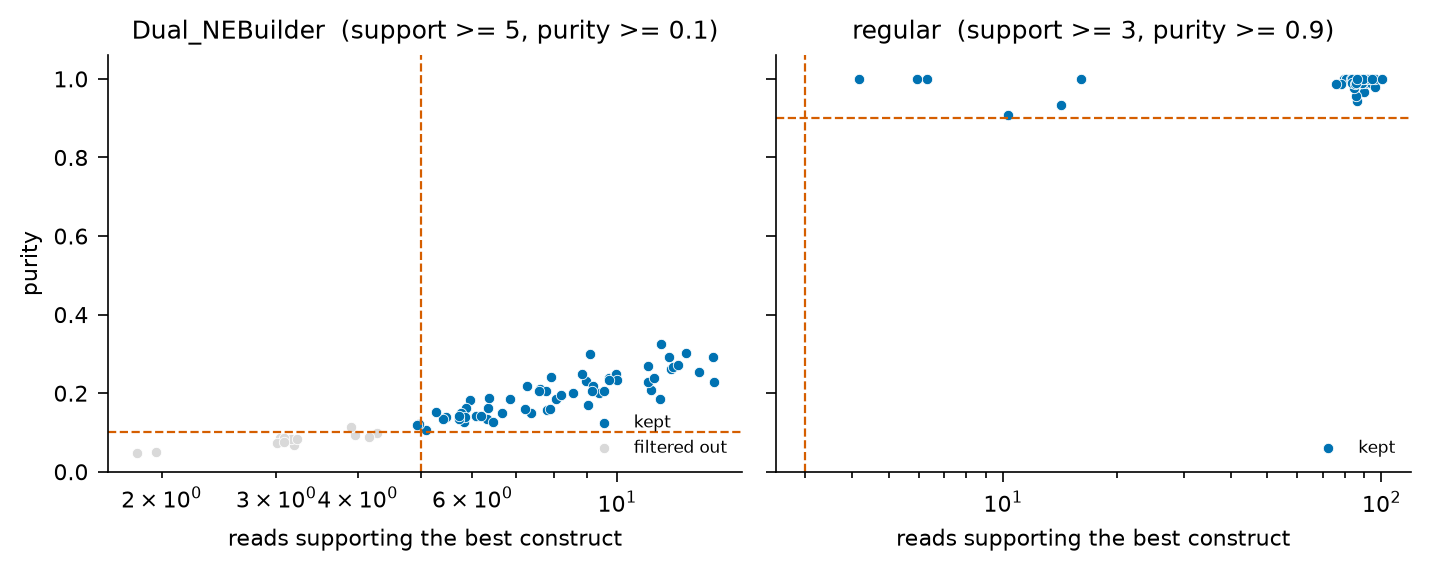

In [7]:
vignette.plot_dictionary(raws, figures / "dictionary.png")
display(Image(filename=str(figures / "dictionary.png")))

## Part 2, counting edits in the cDNA

A base editor can edit the barcode itself, so `step1_expand_barcodes.py` expands each dictionary barcode into the forms it could take.
`step2_count_edits.py` anchors the edit template, calls an edit at every position that can carry one, and credits the read to its barcode's construct.

`--primary_pos 14` pins the on-target position to position 14 of the template.
Left alone the script picks whichever position was edited most, which varies between samples.

In [8]:
parsed_paths = {}
for name in vignette.DATASETS:
    print(f"\n{name}")
    parsed_paths[name], cdna_tally = vignette.count_edits(name, dictionaries[name], work)
    tallies[name].update(cdna_tally)

pd.read_csv(parsed_paths["Dual_NEBuilder"]).head()


Dual_NEBuilder
  step1_expand_barcodes.py


  step2_count_edits.py



regular
  step1_expand_barcodes.py


  step2_count_edits.py


,Outcome,Total_reads,Is_edited,Any_edit_ct,Primary_pos,Primary_edit_ct,Pos1,Pos3,Pos6,Pos14,Pos22,Pos26,Pos29,Pos32,Pos35,Pos37,Pos38,Pos43,Pos45,Pos48
0,RAD51C---D109D,180,10,20,14,10,5,0,0,10,0,0,0,0,0,0,0,0,0,5
1,RAD51C---D109G,158,0,0,14,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
2,RAD51C---D109L,100,11,11,14,8,0,0,0,8,0,3,0,0,0,0,0,0,0,0
3,RAD51C---D109Y,491,11,17,14,9,0,6,1,9,0,0,0,0,0,0,0,1,0,0
4,RAD51C---G112A,190,2,2,14,2,0,0,0,2,0,0,0,0,0,0,0,0,0,0


`Total_reads` is every read credited to the construct, `Primary_edit_ct` those carrying the on-target edit.
The `Pos*` columns count the other editable positions, where off-target editing shows up, and stay out of the counts table.

Where the reads go:

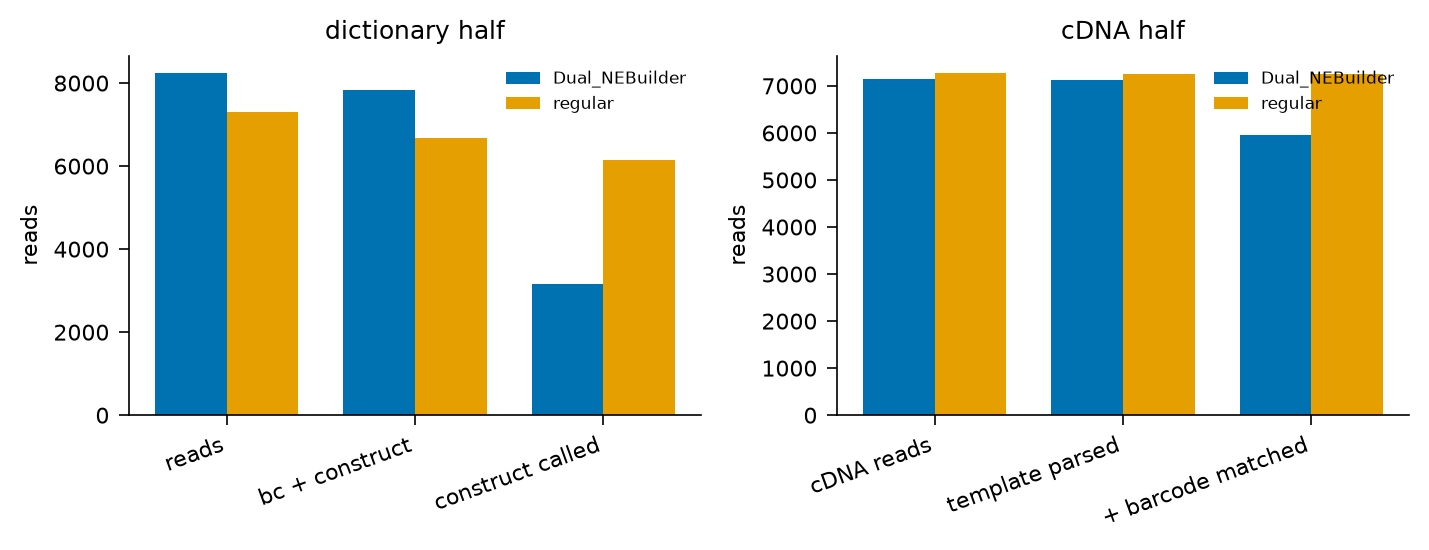

In [9]:
vignette.plot_attrition(tallies, figures / "attrition.png")
display(Image(filename=str(figures / "attrition.png")))

## Check against the expected output

Each dataset ships an `expected_output/` directory: the dictionary and parsed counts from a separate run.

In [10]:
agreed = True
for name, spec in vignette.DATASETS.items():
    expected = vignette.EXAMPLES / name / "expected_output"
    print(name)
    agreed &= vignette.verify(
        "dictionary", dictionaries[name],
        expected / f"{spec['prefix']}.barcode_to_variant.csv.gz",
    )
    agreed &= vignette.verify(
        "cDNA_parsed", parsed_paths[name],
        expected / f"{vignette.SAMPLE}_.cDNA_parsed.csv",
    )

print("\nall files match" if agreed else "\nDISAGREEMENT -- see above")
assert agreed

Dual_NEBuilder
  match    dictionary: 62 rows identical to RAD51C_DMS_1.barcode_to_variant.csv.gz
  match    cDNA_parsed: 27 rows identical to NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv
regular
  match    dictionary: 75 rows identical to RAD51C_DMS_3.barcode_to_variant.csv.gz
  match    cDNA_parsed: 28 rows identical to NR-TV_HCT_RAD51C_XRCC3_Rep1_.cDNA_parsed.csv

all files match


## The counts table

The datasets tile different blocks and share no constructs, and one cDNA sample drove both, so they concatenate into one sample.

In [11]:
parsed = pd.concat([pd.read_csv(p) for p in parsed_paths.values()], ignore_index=True)
counts, samples = vignette.shape_counts(parsed)

dataset = work / "dataset"
dataset.mkdir(exist_ok=True)
counts.to_csv(dataset / "counts.csv", index=False)
samples.to_csv(dataset / "samples.csv", index=False)

pairs = counts.groupby(["bait", "prey"]).ngroups
print(f"{len(counts)} rows, {pairs} pairs, {len(samples)} sample")
counts.head(10)

53 rows, 53 pairs, 1 sample


,sample,bait,prey,total,edited
0,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:D109D,180,10
1,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:D109G,158,0
2,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:D109L,100,8
3,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:D109Y,491,9
4,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:E232E,688,27
5,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:E232G,195,16
6,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:E232K,100,22
7,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:E232T,198,11
8,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:E232V,289,7
9,NR-TV_HCT_RAD51C_XRCC3_Rep1,XRCC3,RAD51C:G112A,190,2


In [12]:
samples

,sample,cell_line,batch,replicate
0,NR-TV_HCT_RAD51C_XRCC3_Rep1,HCT116,041726,1


`total` and `edited` are `Total_reads` and `Primary_edit_ct`.
XRCC3 is the partner throughout, so a pair is one RAD51C construct against it.

Edit rate per construct, and the depth each rate rests on:

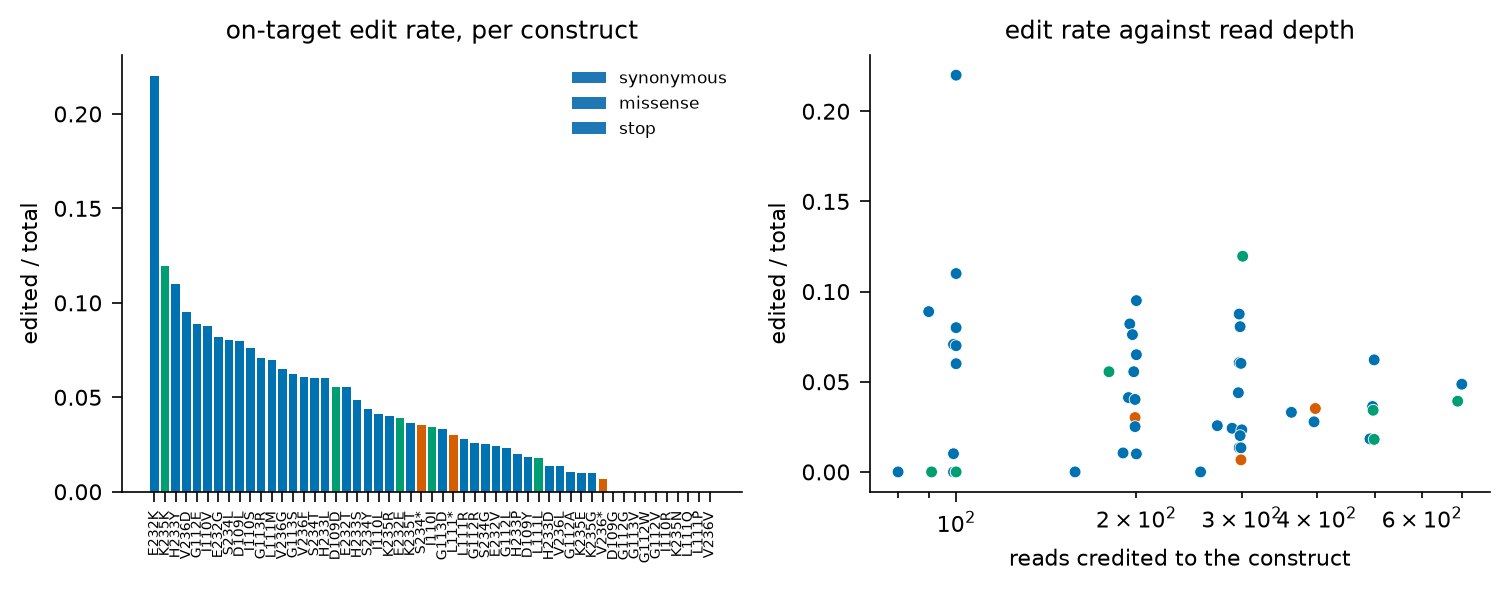

In [13]:
vignette.plot_edit_rates(counts, figures / "edit_rates.png")
display(Image(filename=str(figures / "edit_rates.png")))

## Next

`counts.csv` and `samples.csv` are PyroPPI's whole input contract.

`vignettes/deep_mutational_scanning` fits scans of this kind and calls variants against the synonymous null.
`vignettes/rad51x9` fits an interaction matrix; `vignettes/degrader_screen` fits a screen with no untreated arm.